In [2]:
# Install all required dependencies
!pip install pandas numpy scikit-learn matplotlib seaborn nltk


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [13]:
#Q1

import pandas as pd

# Load dataset without headers using tab delimiter
df = pd.read_csv('amazon_cells_labelled.txt', sep='\t', names=['text', 'sentiment'], header=None)

# Display the first 5 records
df.head()

,text,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [14]:
#Q2

import re
import nltk
from nltk.corpus import stopwords

# Download stopwords list from NLTK
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()
    # Remove punctuation, numbers, and special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Strip unnecessary whitespaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Create clean-text column
df['clean_text'] = df['text'].apply(preprocess_text)

# Compare original and preprocessed text
df[['text', 'clean_text']].head()

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/thevindudilmith/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great


--- Positive Examples ---
['Good case, Excellent value.' 'Great for the jawbone.'
 'The mic is great.']

--- Negative Examples ---
['So there is no way for me to plug it in here in the US unless I go by a converter.'
 'Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!'
 'I have to jiggle the plug to get it to line up right to get decent volume.']


/var/folders/zx/zv9qwgmn36d_53pgkkkhq9hw0000gn/T/ipykernel_4168/1628824171.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[w[1] for w in pos_words], y=[w[0] for w in pos_words], ax=axes[0], palette='Greens_r')
/var/folders/zx/zv9qwgmn36d_53pgkkkhq9hw0000gn/T/ipykernel_4168/1628824171.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[w[1] for w in neg_words], y=[w[0] for w in neg_words], ax=axes[1], palette='Reds_r')


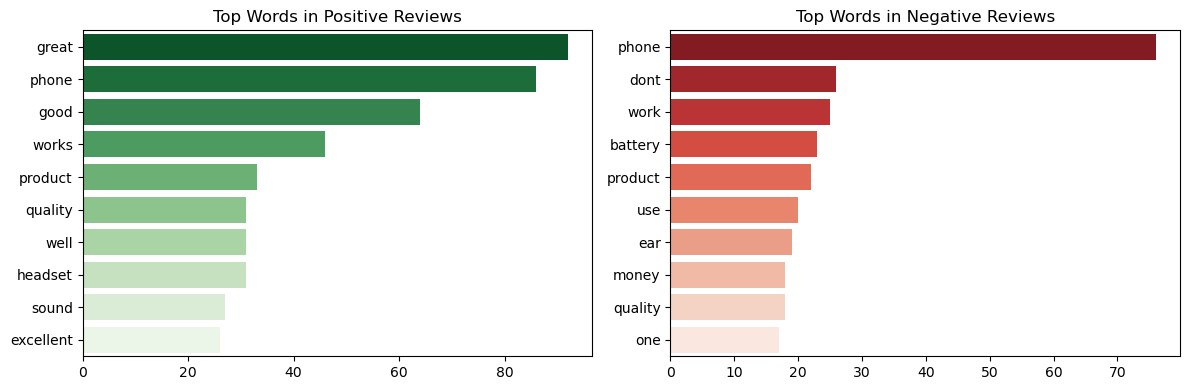

In [15]:
#Q3

from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

# Display positive and negative examples
print("--- Positive Examples ---")
print(df[df['sentiment'] == 1]['text'].head(3).values)

print("\n--- Negative Examples ---")
print(df[df['sentiment'] == 0]['text'].head(3).values)

# Identify frequently occurring words excluding stopwords
def get_top_words(corpus, n=10):
    words = ' '.join(corpus).split()
    words = [w for w in words if w not in stop_words and len(w) > 2]
    return Counter(words).most_common(n)

pos_words = get_top_words(df[df['sentiment'] == 1]['clean_text'])
neg_words = get_top_words(df[df['sentiment'] == 0]['clean_text'])

# Visualize top words using bar plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=[w[1] for w in pos_words], y=[w[0] for w in pos_words], ax=axes[0], palette='Greens_r')
axes[0].set_title('Top Words in Positive Reviews')

sns.barplot(x=[w[1] for w in neg_words], y=[w[0] for w in neg_words], ax=axes[1], palette='Reds_r')
axes[1].set_title('Top Words in Negative Reviews')
plt.tight_layout()
plt.show()

In [16]:
#Q4

from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['sentiment']

# Split dataset into 80% train and 20% test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")

Training samples: 800, Testing samples: 200


In [17]:
#Q5

from sklearn.feature_extraction.text import CountVectorizer

# Convert text documents to a matrix of token counts
vectorizer = CountVectorizer(stop_words='english')
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

In [18]:
#Q6

from sklearn.linear_model import LogisticRegression

# Initialize and train Logistic Regression model
model = LogisticRegression()
model.fit(X_train_bow, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [11]:
#Q7

from sklearn.metrics import accuracy_score, classification_report

# Predict on testing set
y_pred = model.predict(X_test_bow)

# Display evaluation metrics
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive']))

Accuracy: 0.7950

Classification Report:
              precision    recall  f1-score   support

    Negative       0.78      0.82      0.80       100
    Positive       0.81      0.77      0.79       100

    accuracy                           0.80       200
   macro avg       0.80      0.79      0.79       200
weighted avg       0.80      0.80      0.79       200



In [19]:
#Q8

def predict_sentiment(sentence):
    # Preprocess incoming test sentence
    cleaned = preprocess_text(sentence)
    # Transform using fitted vectorizer
    vectorized = vectorizer.transform([cleaned])
    # Predict label
    prediction = model.predict(vectorized)[0]
    return "Positive" if prediction == 1 else "Negative"

# Test sentences
sample_sentences = [
    "Great battery life and clear sound quality.",
    "Waste of money, stopped working after one day."
]

# Run predictions
for s in sample_sentences:
    print(f"Sentence: '{s}' -> Prediction: {predict_sentiment(s)}")

Sentence: 'Great battery life and clear sound quality.' -> Prediction: Positive
Sentence: 'Waste of money, stopped working after one day.' -> Prediction: Negative
